In [10]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier,plot_tree
from sklearn.metrics import confusion_matrix,classification_report

In [5]:
df=pd.read_csv("Admission_Predict.csv")
print(df.columns.to_list())
df["Chance of Admit "]=(df["Chance of Admit "]>=0.8).astype(int)

['Serial No.', 'GRE Score', 'TOEFL Score', 'University Rating', 'SOP', 'LOR ', 'CGPA', 'Research', 'Chance of Admit ']


In [6]:
x=df.drop(['Chance of Admit ','Serial No.'],axis=1)
y=df['Chance of Admit ']
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.25,random_state=42)

In [7]:
model=DecisionTreeClassifier(random_state=123)
model.fit(x_train,y_train)
y_pred=model.predict(x_test)

In [9]:
print("confusion matrix : ",confusion_matrix(y_test,y_pred))
print("classification_report:",classification_report(y_test,y_pred))

confusion matrix :  [[63  3]
 [ 6 28]]
classification_report:               precision    recall  f1-score   support

           0       0.91      0.95      0.93        66
           1       0.90      0.82      0.86        34

    accuracy                           0.91       100
   macro avg       0.91      0.89      0.90       100
weighted avg       0.91      0.91      0.91       100



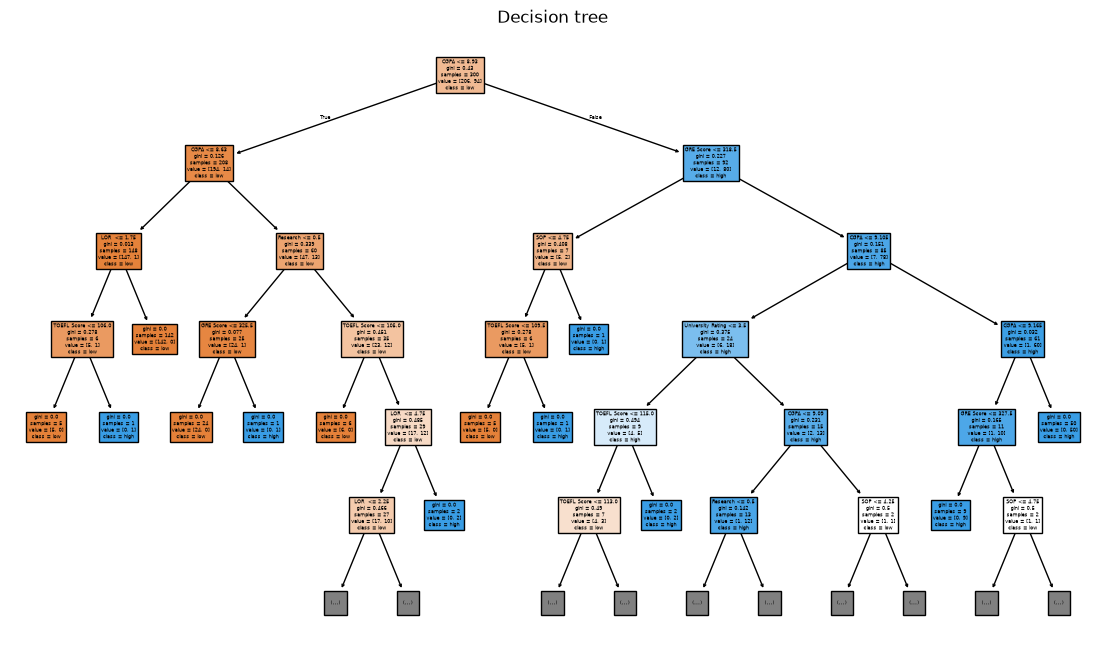

In [11]:
plt.figure(figsize=(14,8))
plot_tree(model,feature_names=x.columns,class_names=['low','high'],filled=True,max_depth=5)
plt.title("Decision tree")
plt.show()